<a href="https://colab.research.google.com/github/tazar09/h3_public_repo/blob/main/building-networkX_13-oct2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Requirements

In [ ]:
import random
import pandas as pd
import matplotlib as plt
import networkx as nx

#Towns

In [190]:
# Define multiple towns/factions using a dictionary keyed by faction name
towns = {
    "Cove": {
        "faction": "Cove",
        "source": "Fill in with your source",
        "buildings": [
            {"id": "blacksmith", "name": "Blacksmith", "requires": []},
            {"id": "MG_1", "name": "MG_1", "requires": []},
            {"id": "MG_2", "name": "MG_2", "requires": ["MG_1"]},

            {"id": "Upgraded Nymph Waterfall", "name": "Upgraded Level_1", "requires": []},
            {"id": "Upgraded Shack", "name": "Upgraded Level_2", "requires": []},
            {"id": "Frigate", "name": "Level_3", "requires": ["blacksmith"]},
            {"id": "Nest", "name": "Level_4", "requires": []},
            {"id": "Tower of the Seas", "name": "Level_5", "requires": ["MG_1"]},
            {"id": "Upgraded Tower of the Seas", "name": "Upgraded Level_5", "requires": ["MG_2"]},
            {"id": "Nix Fort", "name": "Level_6", "requires": ["Nest","Tower of the Seas"]},
            {"id": "Maelstrom", "name": "Level_7", "requires": ["Tower of the Seas", "Nix Fort"]},
            {"id": "Upgraded Maelstrom", "name": "Upgraded Level_7", "requires": ["Maelstrom", "MG_2"]}
        ]
    },
    "Fortress": {
        "faction": "Fortress",
        "source": "Official Wiki",
        "buildings": [
            # {"id": "tavern", "name": "Tavern", "requires": []},
            {"id": "market", "name": "Market", "requires": []},
            {"id": "res_silo", "name": "Res_silo", "requires": ["market"]},
            # {"id": "blacksmith", "name": "Blacksmith", "requires": []},
            # {"id": "MG_1", "name": "MG_1", "requires": []},
            # {"id": "MG_2", "name": "MG_2", "requires": ["MG_1"]},

            {"id": "Upgraded Gnoll Hut", "name": "Upgraded Level_1", "requires": []},
            {"id": "Upgraded Lizard Den", "name": "Upgraded Level_2", "requires": []},
            {"id": "Serpent Fly Hive", "name": "Level_3", "requires": []},
            {"id": "Basilisk Pit", "name": "Level_4", "requires": ["Serpent Fly Hive"]},
            {"id": "Gorgon Lair", "name": "Level_5", "requires": ["Serpent Fly Hive"]},
            {"id": "Upgraded Gorgon Lair", "name": "Upgraded Level_5", "requires": ["Gorgon Lair","res_silo"]},
            {"id": "Wyvern Nest", "name": "Level_6", "requires": [],},
            {"id": "Hydra Pond", "name": "Level_7", "requires": ["Basilisk Pit", "Wyvern Nest"]}
                    ]
    },

    "Stronghold": {
        "faction": "Strongold",
        "source": "Official Wiki",
        "buildings": [
            # {"id": "tavern", "name": "Tavern", "requires": []},
            # {"id": "market", "name": "Market", "requires": []},
            # {"id": "res_silo", "name": "Res_silo", "requires": ["market"]},
            {"id": "blacksmith", "name": "Blacksmith", "requires": []},
            {"id": "MG_1", "name": "MG_1", "requires": []},
            # {"id": "MG_2", "name": "MG_2", "requires": ["MG_1"]},

            {"id": "Upgraded Goblin Barracks", "name": "Upgraded Level_1", "requires": []},
            {"id": "Upgraded Wolf Pen", "name": "Upgraded Level_2", "requires": ["Upgraded Goblin Barracks"]},
            {"id": "Orc Tower", "name": "Level_3", "requires": []},
            {"id": "Upgraded Orc Tower", "name": "Upgraded Level_3", "requires": ['Orc Tower', 'blacksmith']},
            {"id": "Ogre Fort", "name": "Level_4", "requires": ["Orc Tower"]},
            {"id": "Upgraded Ogre Fort", "name": "Upgraded Level_4", "requires": ["Ogre Fort", "MG_1"]},
            {"id": "Cliff Nest", "name": "Level_5", "requires": []},
            {"id": "Cyclops Cave", "name": "Level_6", "requires": ["Ogre Fort"]},
            {"id": "Behemoth Lair", "name": "Level_7", "requires": ["Cliff Nest"]}
            # Add other Castle buildings and dependencies here
                     ]
    }
}



#Selection

In [191]:
# To select a faction to plot, you can simply extract it like this:
town = towns["Stronghold"]

#Plot

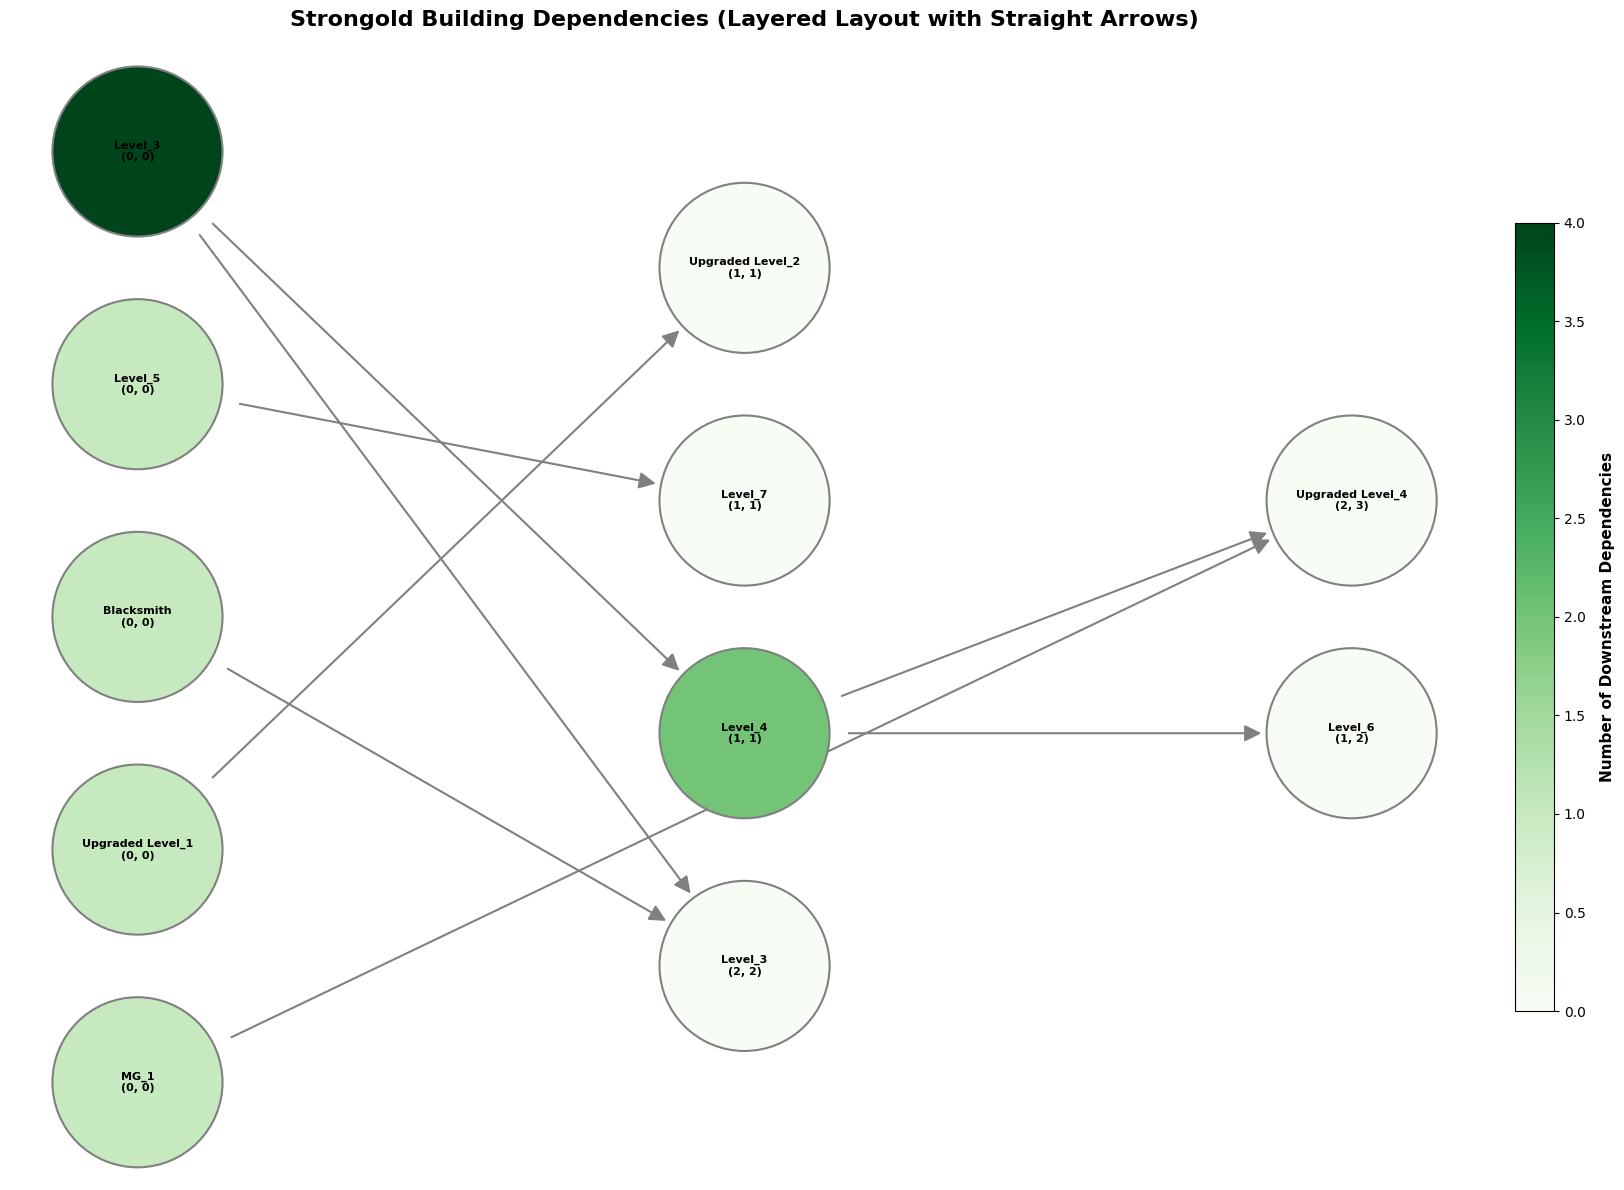

In [192]:

# 1. Build a fresh directed graph from the currently selected 'town'
graph = nx.DiGraph()
for building in town["buildings"]:
    building_id = building["id"]
    graph.add_node(building_id, label=building["name"])
    for prerequisite in building["requires"]:
        graph.add_edge(prerequisite, building_id)

# 2. Calculate the hierarchical layer (depth) of each building
layers = {}
def get_node_layer(node):
    if node in layers:
        return layers[node]
    preds = list(graph.predecessors(node))
    if not preds:
        layers[node] = 0
        return 0
    layer_val = 1 + max(get_node_layer(p) for p in preds)
    layers[node] = layer_val
    return layer_val

for node in graph.nodes():
    get_node_layer(node)

# Assign the calculated layer attribute to each node
for node, layer_val in layers.items():
    graph.nodes[node]['layer'] = layer_val

# 3. Calculate the downstream counts for coloring (we keep this for node color intensity if desired, or can color by total dependencies)
node_list = list(graph.nodes())
downstream_counts = {
    node: len(nx.descendants(graph, node))
    for node in node_list
}
colors = [downstream_counts[node] for node in node_list]

# Calculate total upstream dependencies (ancestors) for each node
total_dependencies = {
    node: len(nx.ancestors(graph, node))
    for node in node_list
}

# 4. Build an ID-to-label lookup displaying name, direct prerequisites, and total dependencies
labels = {
    building["id"]: f"{building['name']}\n({len(building['requires'])}, {total_dependencies[building['id']]})"
    for building in town["buildings"]
}

# 5. Use a multipartite layout to align nodes beautifully in columns by their layer
positions_layered = nx.multipartite_layout(graph, subset_key="layer", align="vertical")

# Adjust the spacing manually to ensure nodes are not vertically crowded
for node in positions_layered:
    positions_layered[node][0] *= 2.5  # Spread columns out wider horizontally

# Set a clean figure size
plt.figure(figsize=(18, 12))

# Draw nodes using a vibrant Greens palette - increased node_size to 15000
sc = nx.draw_networkx_nodes(
    graph,
    positions_layered,
    nodelist=node_list,
    node_size=15000,
    node_color=colors,
    cmap=plt.cm.Greens,
    edgecolors="gray",
    linewidths=1.5
)

# Draw edges with straight arrows (removing the connectionstyle arc configuration)
nx.draw_networkx_edges(
    graph,
    positions_layered,
    arrows=True,
    arrowstyle="-|>",
    arrowsize=25,
    width=1.5,
    edge_color="gray",
    min_source_margin=75,
    min_target_margin=65
)

# Draw node labels
nx.draw_networkx_labels(
    graph,
    positions_layered,
    labels=labels,
    font_size=8,
    font_weight="bold"
)

# Add a colorbar
cbar = plt.colorbar(sc, shrink=0.7, aspect=20, pad=0.02)
cbar.set_label("Number of Downstream Dependencies", fontsize=11, fontweight="bold", labelpad=10)

plt.title(f'{town["faction"]} Building Dependencies (Layered Layout with Straight Arrows)', fontsize=16, fontweight="bold", pad=20)
plt.axis("off")
plt.tight_layout()
plt.show()


#Final